# Physics-Informed Neural Networks (PINNs) vs. Standard Neural Networks

**Teaching a neural network the laws of physics — and showing why it matters when data is scarce.**

A standard neural network learns a function purely from examples. A **Physics-Informed Neural Network** (Raissi, Perdikaris & Karniadakis, 2019) adds a second source of supervision: the governing differential equation itself. Using automatic differentiation, we compute the derivatives of the network's output with respect to its *inputs* and penalise any violation of the physics at thousands of "collocation" points where no measurements exist.

This notebook builds PINNs from scratch in PyTorch and compares them, head-to-head, against an otherwise identical network trained without the physics term.

| # | Problem | Type | Question |
|---|---------|------|----------|
| 1 | Damped harmonic oscillator (ODE) | Forward | Can the model extrapolate beyond the observed window? |
| 2 | Damped harmonic oscillator (ODE) | **Inverse** | Can we discover an unknown physical parameter from noisy data? |
| 3 | 1-D heat equation (PDE) | Forward | Can the model reconstruct a full space-time field from 5 sensors? |

**Fair-comparison principle:** in every experiment the baseline NN and the PINN share the same architecture, initial weights, data, optimiser and number of steps. *The only difference is the physics residual term in the loss.*

> Runtime: roughly 3–6 minutes on a laptop CPU, under 2 minutes on a GPU.

## 0. Setup

In [1]:
import os
import time

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import Image, display

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_default_dtype(torch.float32)

FIG_DIR = "figures"            # every figure is also saved here (handy for a README)
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "legend.frameon": False,
})
C = {"exact": "#2b2d42", "nn": "#d1495b", "pinn": "#1f78b4",
     "data": "#f4a259", "colloc": "#8d99ae", "window": "#f4a259"}

def savefig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), bbox_inches="tight")

def set_seed(seed=SEED):
    torch.manual_seed(seed)
    np.random.seed(seed)

def to_tensor(a, requires_grad=False):
    return torch.tensor(np.asarray(a), dtype=torch.float32, device=DEVICE, requires_grad=requires_grad)

def rel_l2(pred, true):
    return float(np.linalg.norm(pred - true) / np.linalg.norm(true))

print(f"PyTorch {torch.__version__} | device: {DEVICE}")

PyTorch 2.8.0+cu129 | device: cuda


### Shared building blocks

**Network.** A fully connected network with `tanh` activations. The choice of activation matters for PINNs: the loss contains *second* derivatives of the network, and `ReLU` has a second derivative of zero almost everywhere, so it cannot represent $u''$. `tanh` is smooth and infinitely differentiable.

**Derivatives.** `torch.autograd.grad(..., create_graph=True)` gives exact derivatives of the network output with respect to its inputs, and keeps them in the computational graph so the optimiser can back-propagate *through* them.

In [2]:
class MLP(nn.Module):
    # Fully connected network: in_dim -> [width] * depth -> out_dim, tanh activations.
    def __init__(self, in_dim=1, out_dim=1, width=32, depth=3):
        super().__init__()
        layers, d = [], in_dim
        for _ in range(depth):
            layers += [nn.Linear(d, width), nn.Tanh()]
            d = width
        layers.append(nn.Linear(d, out_dim))
        self.net = nn.Sequential(*layers)
        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.net(x)


def grad(outputs, inputs):
    # d(outputs)/d(inputs), kept in the graph so it can itself be differentiated and trained on.
    return torch.autograd.grad(outputs, inputs, grad_outputs=torch.ones_like(outputs),
                               create_graph=True)[0]


def train_adam(model, loss_fn, n_steps, lr=1e-3, lr_final=1e-4, extra_params=None,
               log_every=2000, snapshot_every=None, snapshot_fn=None, tag="model"):
    # Adam with exponential learning-rate decay from lr to lr_final.
    # loss_fn(model) must return (total_loss, {component_name: loss_tensor}).
    groups = [{"params": model.parameters(), "lr": lr}]
    if extra_params:
        groups += extra_params                      # e.g. a learnable physical parameter
    opt = torch.optim.Adam(groups)
    sched = torch.optim.lr_scheduler.ExponentialLR(opt, gamma=(lr_final / lr) ** (1 / n_steps))

    history, snapshots = {"total": []}, []
    t0 = time.perf_counter()
    for step in range(1, n_steps + 1):
        opt.zero_grad()
        loss, parts = loss_fn(model)
        loss.backward()
        opt.step()
        sched.step()

        history["total"].append(loss.item())
        for k, v in parts.items():
            history.setdefault(k, []).append(v.item())
        if snapshot_fn is not None and (step % snapshot_every == 0 or step == 1):
            snapshots.append((step, snapshot_fn(model)))
        if step % log_every == 0 or step == 1:
            comp = "  ".join(f"{k}={v.item():.2e}" for k, v in parts.items())
            print(f"[{tag}] step {step:>6d} | loss={loss.item():.3e} | {comp}")
    elapsed = time.perf_counter() - t0
    print(f"[{tag}] done in {elapsed:.1f}s")
    return history, snapshots, elapsed


def train_lbfgs(model, loss_fn, history, max_iter=500, tag="model"):
    # Second-order refinement, the standard final stage for PINNs.
    opt = torch.optim.LBFGS(model.parameters(), lr=1.0, max_iter=max_iter,
                            max_eval=int(1.25 * max_iter), history_size=50,
                            tolerance_grad=1e-9, tolerance_change=1e-12,
                            line_search_fn="strong_wolfe")
    t0 = time.perf_counter()

    def closure():
        opt.zero_grad()
        loss, parts = loss_fn(model)
        loss.backward()
        history["total"].append(loss.item())
        for k, v in parts.items():
            history.setdefault(k, []).append(v.item())
        return loss

    opt.step(closure)
    elapsed = time.perf_counter() - t0
    print(f"[{tag}] L-BFGS done in {elapsed:.1f}s | final loss={history['total'][-1]:.3e}")
    return elapsed

---
## 1. Forward problem — the damped harmonic oscillator

### The physics
A mass $m$ on a spring of stiffness $k$ with viscous damping $c$:

$$
m\,\frac{d^2u}{dt^2} + c\,\frac{du}{dt} + k\,u = 0,
\qquad u(0) = 1,\qquad \frac{du}{dt}(0) = 0 .
$$

For the under-damped case ($\delta < \omega_0$) the exact solution is

$$
u(t) = e^{-\delta t}\left(\cos\omega t + \frac{\delta}{\omega}\sin\omega t\right),
\qquad \delta = \frac{c}{2m},\quad \omega_0 = \sqrt{\frac{k}{m}},\quad \omega = \sqrt{\omega_0^2-\delta^2}.
$$

We use $m=1,\ c=4,\ k=400$ (so $\delta=2$, $\omega_0=20$): about three full oscillations on $t\in[0,1]$.

### The challenge
We only observe **10 noisy measurements in the first 40% of the time window** ($t \le 0.4$). The task is to predict the motion over the whole interval $[0, 1]$, i.e. to **extrapolate**.

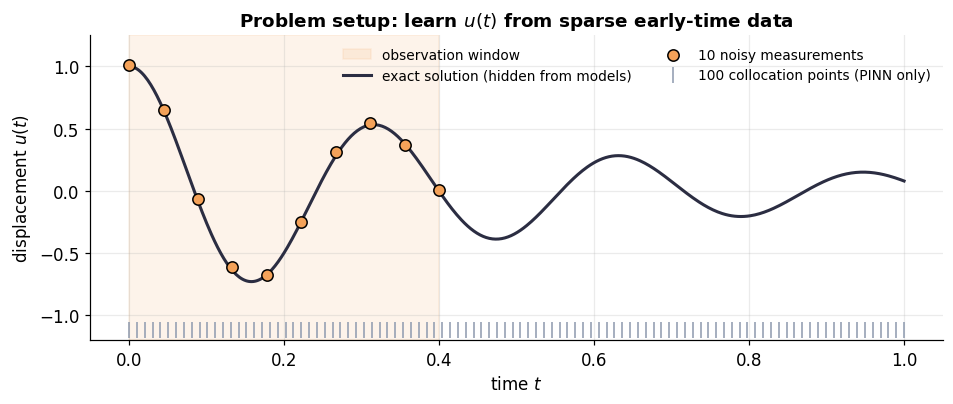

In [3]:
# Physical parameters
m, c_true, k = 1.0, 4.0, 400.0
delta = c_true / (2 * m)
omega0 = np.sqrt(k / m)
omega = np.sqrt(omega0**2 - delta**2)

def exact_oscillator(t):
    return np.exp(-delta * t) * (np.cos(omega * t) + (delta / omega) * np.sin(omega * t))

T_MAX = 1.0
t_test = np.linspace(0, T_MAX, 500)[:, None]
u_test = exact_oscillator(t_test)

# Sparse, noisy observations inside a limited window
set_seed()
N_DATA, T_OBS, NOISE = 10, 0.4, 0.02
t_data = np.linspace(0, T_OBS, N_DATA)[:, None]
u_data = exact_oscillator(t_data) + NOISE * np.random.randn(*t_data.shape)

# Collocation points: where the physics is enforced (no labels needed!)
N_COLLOC = 100
t_colloc = np.linspace(0, T_MAX, N_COLLOC)[:, None]

# Tensors
t_data_t, u_data_t = to_tensor(t_data), to_tensor(u_data)
t_colloc_t = to_tensor(t_colloc, requires_grad=True)
t0_t = to_tensor([[0.0]], requires_grad=True)
t_test_t = to_tensor(t_test)

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.axvspan(0, T_OBS, color=C["window"], alpha=0.12, label="observation window")
ax.plot(t_test, u_test, color=C["exact"], lw=2, label="exact solution (hidden from models)")
ax.scatter(t_data, u_data, color=C["data"], edgecolor="k", s=55, zorder=5, label=f"{N_DATA} noisy measurements")
ax.plot(t_colloc, np.full_like(t_colloc, -1.12), "|", color=C["colloc"], ms=10,
        label=f"{N_COLLOC} collocation points (PINN only)")
ax.set(xlabel="time $t$", ylabel="displacement $u(t)$", title="Problem setup: learn $u(t)$ from sparse early-time data",
       ylim=(-1.2, 1.25))
ax.legend(loc="upper right", ncol=2, fontsize=9)
savefig(fig, "01_oscillator_setup"); plt.show()

### The loss functions

Let $\hat u_\theta(t)$ be the network with weights $\theta$.

**Standard NN** — fit the measurements and the initial conditions:

$$
\mathcal{L}_{\text{NN}}(\theta) =
\underbrace{\frac{1}{N_d}\sum_{i=1}^{N_d}\big(\hat u_\theta(t_i) - u_i\big)^2}_{\mathcal{L}_{\text{data}}}
\;+\;\lambda_{\text{ic}}\underbrace{\Big[\big(\hat u_\theta(0)-1\big)^2 + \Big(\tfrac{1}{\omega_0}\hat u_\theta'(0)\Big)^2\Big]}_{\mathcal{L}_{\text{ic}}}
$$

**PINN** — the same, *plus* the residual of the ODE evaluated at $N_c$ collocation points $\{t_j\}$ spread over the whole domain:

$$
\mathcal{L}_{\text{PINN}}(\theta) = \mathcal{L}_{\text{data}} + \lambda_{\text{ic}}\,\mathcal{L}_{\text{ic}}
\;+\;\lambda_{\text{phys}}\underbrace{\frac{1}{N_c}\sum_{j=1}^{N_c} \hat r_\theta(t_j)^2}_{\mathcal{L}_{\text{phys}}},
\qquad
\hat r_\theta(t) = \frac{1}{k}\Big(m\,\hat u_\theta''(t) + c\,\hat u_\theta'(t) + k\,\hat u_\theta(t)\Big).
$$

Two practical details that make or break PINN training:

* **Non-dimensionalisation.** The raw residual scales with $k = 400$, so its square is $\sim10^5$ times larger than the data loss and would swamp it. Dividing by $k$ (and the derivative condition by $\omega_0$) brings every term to $\mathcal{O}(1)$.
* **No labels at collocation points.** $\mathcal{L}_{\text{phys}}$ needs only the input $t_j$. The physics acts as an *infinite, free source of supervision* wherever we choose to sample it.

In [4]:
LAMBDA_IC, LAMBDA_PHYS = 1.0, 10.0

def oscillator_residual(model, t, c=c_true):
    u = model(t)
    du = grad(u, t)
    d2u = grad(du, t)
    return (m * d2u + c * du + k * u) / k          # non-dimensional residual

def oscillator_loss(model, use_physics):
    loss_data = torch.mean((model(t_data_t) - u_data_t) ** 2)

    u0 = model(t0_t)
    du0 = grad(u0, t0_t)
    loss_ic = torch.mean((u0 - 1.0) ** 2) + torch.mean((du0 / omega0) ** 2)

    parts = {"data": loss_data, "ic": loss_ic}
    total = loss_data + LAMBDA_IC * loss_ic
    if use_physics:                                  # <- the ONLY difference between the two models
        loss_phys = torch.mean(oscillator_residual(model, t_colloc_t) ** 2)
        parts["physics"] = loss_phys
        total = total + LAMBDA_PHYS * loss_phys
    return total, parts

def predict_1d(model):
    with torch.no_grad():
        return model(t_test_t).cpu().numpy()

### Training

Both models: 3 hidden layers × 32 neurons, identical initial weights, Adam with learning rate decaying $10^{-3}\to10^{-4}$ over 20 000 steps.

In [5]:
N_STEPS_OSC = 20_000

set_seed(); nn_osc = MLP(1, 1, width=32, depth=3).to(DEVICE)
set_seed(); pinn_osc = MLP(1, 1, width=32, depth=3).to(DEVICE)   # identical initial weights

hist_nn_osc, snaps_nn_osc, time_nn_osc = train_adam(
    nn_osc, lambda mdl: oscillator_loss(mdl, use_physics=False), N_STEPS_OSC,
    snapshot_every=500, snapshot_fn=predict_1d, tag="NN  ")

hist_pinn_osc, snaps_pinn_osc, time_pinn_osc = train_adam(
    pinn_osc, lambda mdl: oscillator_loss(mdl, use_physics=True), N_STEPS_OSC,
    snapshot_every=500, snapshot_fn=predict_1d, tag="PINN")

c:\Users\annab\AppData\Local\Programs\Python\Python310\lib\site-packages\torch\autograd\graph.py:829: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\cuda\CublasHandlePool.cpp:179.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


[NN  ] step      1 | loss=1.284e+00 | data=2.83e-01  ic=1.00e+00
[NN  ] step   2000 | loss=2.066e-04 | data=2.06e-04  ic=3.54e-07
[NN  ] step   4000 | loss=2.163e-05 | data=2.13e-05  ic=3.00e-07
[NN  ] step   6000 | loss=1.508e-05 | data=1.45e-05  ic=6.21e-07
[NN  ] step   8000 | loss=1.178e-05 | data=1.06e-05  ic=1.13e-06
[NN  ] step  10000 | loss=1.607e-05 | data=1.49e-05  ic=1.16e-06
[NN  ] step  12000 | loss=9.356e-06 | data=8.41e-06  ic=9.49e-07
[NN  ] step  14000 | loss=1.002e-05 | data=9.88e-06  ic=1.40e-07
[NN  ] step  16000 | loss=1.041e-05 | data=1.03e-05  ic=1.18e-07
[NN  ] step  18000 | loss=8.991e-06 | data=8.32e-06  ic=6.69e-07
[NN  ] step  20000 | loss=8.975e-06 | data=8.17e-06  ic=8.04e-07
[NN  ] done in 117.6s
[PINN] step      1 | loss=1.675e+00 | data=2.83e-01  ic=1.00e+00  physics=3.92e-02
[PINN] step   2000 | loss=1.357e-02 | data=1.30e-03  ic=1.12e-04  physics=1.22e-03
[PINN] step   4000 | loss=7.052e-03 | data=4.26e-04  ic=5.13e-06  physics=6.62e-04
[PINN] step   

### Results

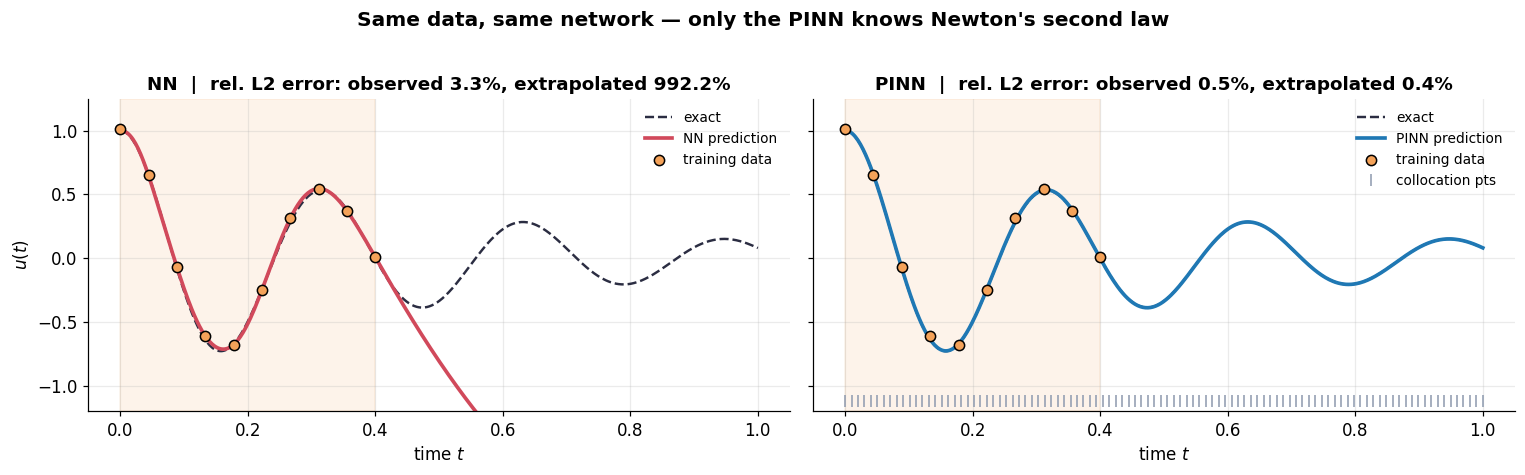

model     error (t <= 0.4)     error (t > 0.4)
NN                   3.32%             992.21%
PINN                 0.45%               0.35%


In [6]:
u_nn = predict_1d(nn_osc)
u_pinn = predict_1d(pinn_osc)
obs = t_test[:, 0] <= T_OBS

metrics_osc = {
    "NN":   {"observed": rel_l2(u_nn[obs], u_test[obs]),   "extrapolated": rel_l2(u_nn[~obs], u_test[~obs])},
    "PINN": {"observed": rel_l2(u_pinn[obs], u_test[obs]), "extrapolated": rel_l2(u_pinn[~obs], u_test[~obs])},
}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for ax, name, pred, color in [(axes[0], "NN", u_nn, C["nn"]), (axes[1], "PINN", u_pinn, C["pinn"])]:
    ax.axvspan(0, T_OBS, color=C["window"], alpha=0.12)
    ax.plot(t_test, u_test, "--", color=C["exact"], lw=1.6, label="exact")
    ax.plot(t_test, pred, color=color, lw=2.4, label=f"{name} prediction")
    ax.scatter(t_data, u_data, color=C["data"], edgecolor="k", s=45, zorder=5, label="training data")
    if name == "PINN":
        ax.plot(t_colloc, np.full_like(t_colloc, -1.12), "|", color=C["colloc"], ms=8, label="collocation pts")
    e = metrics_osc[name]
    ax.set_title(f"{name}  |  rel. L2 error: observed {e['observed']:.1%}, extrapolated {e['extrapolated']:.1%}")
    ax.set(xlabel="time $t$", ylim=(-1.2, 1.25))
    ax.legend(loc="upper right", fontsize=9)
axes[0].set_ylabel("$u(t)$")
fig.suptitle("Same data, same network — only the PINN knows Newton's second law", fontweight="bold", y=1.02)
fig.tight_layout(); savefig(fig, "02_oscillator_comparison"); plt.show()

print(f"{'model':<6}{'error (t <= 0.4)':>20}{'error (t > 0.4)':>20}")
for name, e in metrics_osc.items():
    print(f"{name:<6}{e['observed']:>20.2%}{e['extrapolated']:>20.2%}")

### How the two models learn

Snapshots during training. The standard NN quickly fits the 10 points, but its behaviour outside the observation window is arbitrary. The PINN starts the same way, then the physics residual progressively "propagates" the solution forward in time — a well-known PINN behaviour, since the residual can only be satisfied once the earlier part of the trajectory is right.

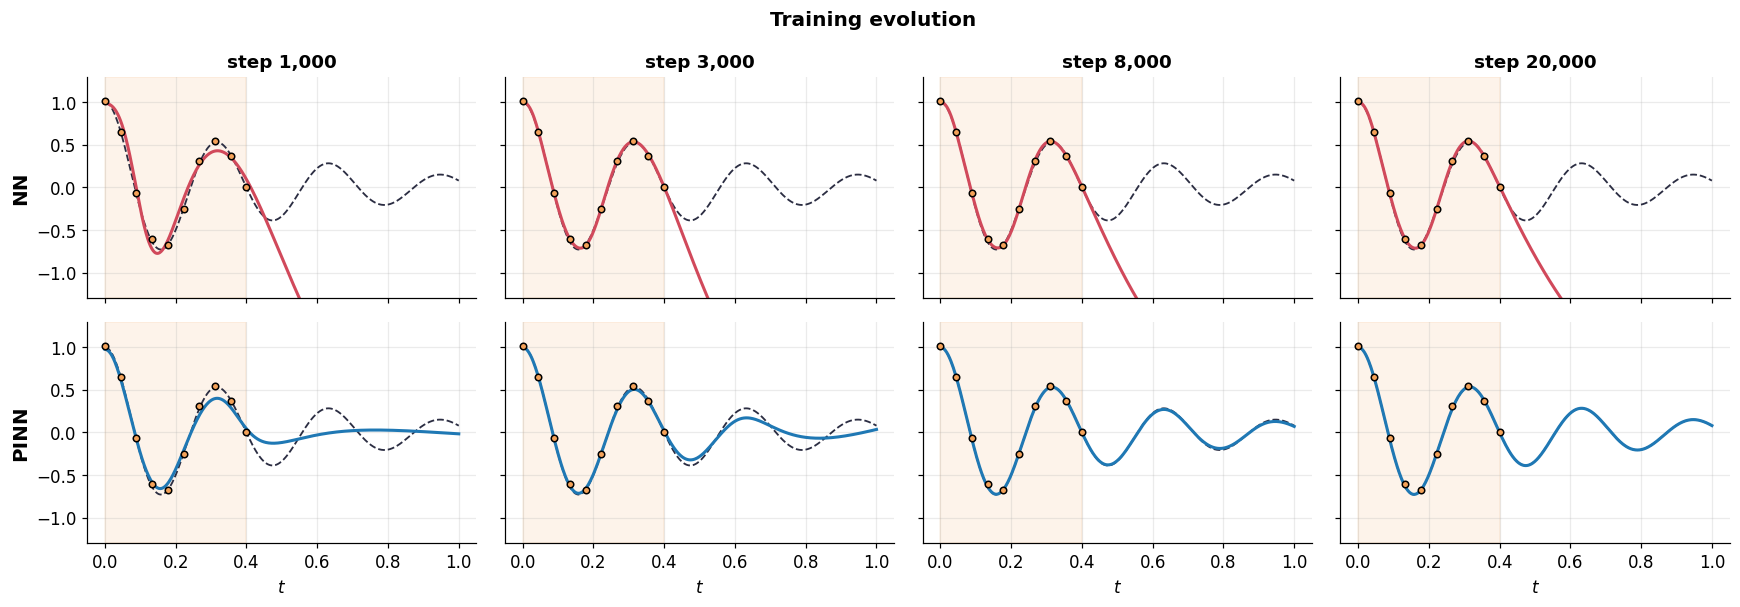

In [7]:
show_steps = [1000, 3000, 8000, N_STEPS_OSC]
snap_nn, snap_pinn = dict(snaps_nn_osc), dict(snaps_pinn_osc)

fig, axes = plt.subplots(2, len(show_steps), figsize=(16, 5.6), sharex=True, sharey=True)
for j, s in enumerate(show_steps):
    for i, (name, snaps, color) in enumerate([("NN", snap_nn, C["nn"]), ("PINN", snap_pinn, C["pinn"])]):
        ax = axes[i, j]
        ax.axvspan(0, T_OBS, color=C["window"], alpha=0.12)
        ax.plot(t_test, u_test, "--", color=C["exact"], lw=1.2)
        ax.plot(t_test, snaps[s], color=color, lw=2)
        ax.scatter(t_data, u_data, color=C["data"], edgecolor="k", s=18, zorder=5)
        ax.set_ylim(-1.3, 1.3)
        if i == 0: ax.set_title(f"step {s:,}")
        if j == 0: ax.set_ylabel(name, fontweight="bold", fontsize=13)
        if i == 1: ax.set_xlabel("$t$")
fig.suptitle("Training evolution", fontweight="bold")
fig.tight_layout(); savefig(fig, "03_oscillator_training_snapshots"); plt.show()

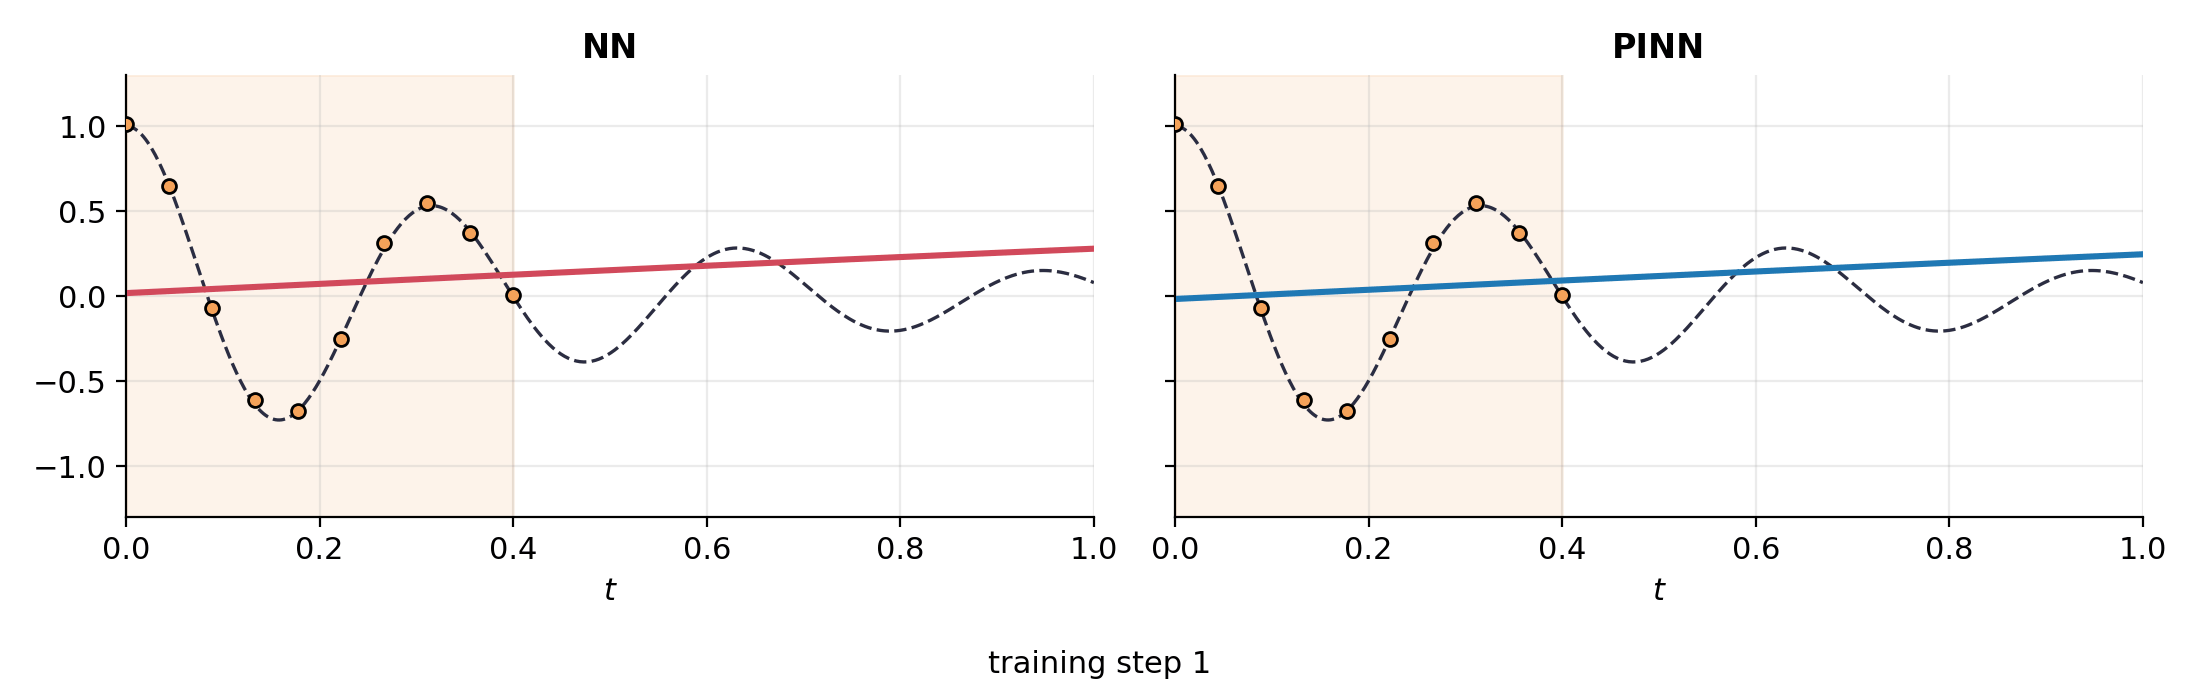

In [8]:
# Animated version of the snapshots (saved as a GIF, ideal for a README or LinkedIn post)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
lines = []
for ax, name, color in [(axes[0], "NN", C["nn"]), (axes[1], "PINN", C["pinn"])]:
    ax.axvspan(0, T_OBS, color=C["window"], alpha=0.12)
    ax.plot(t_test, u_test, "--", color=C["exact"], lw=1.2)
    ax.scatter(t_data, u_data, color=C["data"], edgecolor="k", s=25, zorder=5)
    (ln,) = ax.plot([], [], color=color, lw=2.2)
    lines.append(ln)
    ax.set(title=name, xlabel="$t$", xlim=(0, T_MAX), ylim=(-1.3, 1.3))
step_label = fig.text(0.5, 0.01, "", ha="center")
fig.tight_layout(rect=(0, 0.05, 1, 1))

def update(i):
    lines[0].set_data(t_test[:, 0], snaps_nn_osc[i][1][:, 0])
    lines[1].set_data(t_test[:, 0], snaps_pinn_osc[i][1][:, 0])
    step_label.set_text(f"training step {snaps_pinn_osc[i][0]:,}")
    return (*lines, step_label)

anim = animation.FuncAnimation(fig, update, frames=len(snaps_pinn_osc), interval=120, blit=False)
gif_path = os.path.join(FIG_DIR, "04_oscillator_training.gif")
anim.save(gif_path, writer=animation.PillowWriter(fps=8))
plt.close(fig)
display(Image(filename=gif_path))

### Loss curves and *why* the PINN wins

The left panels show the loss components. The right panels look inside the models:

* **Pointwise error** $|\hat u - u|$ — both models are accurate inside the observation window, but only the PINN stays accurate after it.
* **Physics residual** $|\hat r(t)|$ — evaluated for *both* models. The standard NN fits the data but badly violates the governing equation; the PINN satisfies it everywhere. This is the key diagnostic: low data error does **not** imply a physically valid model.

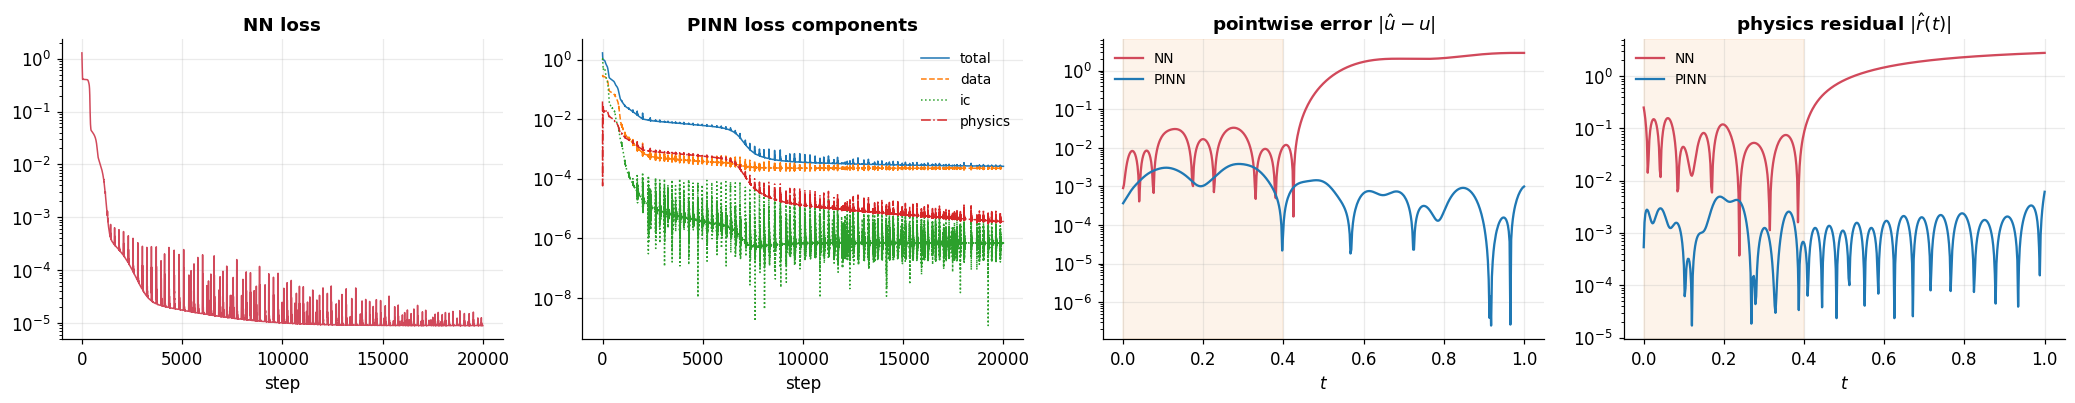

Mean |residual|  NN: 1.088e+00   PINN: 1.482e-03


In [9]:
def residual_on_grid(model):
    t = to_tensor(t_test, requires_grad=True)
    return oscillator_residual(model, t).detach().cpu().numpy()

r_nn, r_pinn = residual_on_grid(nn_osc), residual_on_grid(pinn_osc)

fig, axes = plt.subplots(1, 4, figsize=(19, 3.8))
ax = axes[0]
ax.semilogy(hist_nn_osc["total"], color=C["nn"], lw=1)
ax.set(title="NN loss", xlabel="step")
ax = axes[1]
for key, ls in [("total", "-"), ("data", "--"), ("ic", ":"), ("physics", "-.")]:
    ax.semilogy(hist_pinn_osc[key], ls, lw=1, label=key)
ax.set(title="PINN loss components", xlabel="step"); ax.legend(fontsize=9)

ax = axes[2]
ax.axvspan(0, T_OBS, color=C["window"], alpha=0.12)
ax.semilogy(t_test, np.abs(u_nn - u_test), color=C["nn"], label="NN")
ax.semilogy(t_test, np.abs(u_pinn - u_test), color=C["pinn"], label="PINN")
ax.set(title=r"pointwise error $|\hat u - u|$", xlabel="$t$"); ax.legend(fontsize=9)

ax = axes[3]
ax.axvspan(0, T_OBS, color=C["window"], alpha=0.12)
ax.semilogy(t_test, np.abs(r_nn), color=C["nn"], label="NN")
ax.semilogy(t_test, np.abs(r_pinn), color=C["pinn"], label="PINN")
ax.set(title=r"physics residual $|\hat r(t)|$", xlabel="$t$"); ax.legend(fontsize=9)

fig.tight_layout(); savefig(fig, "05_oscillator_diagnostics"); plt.show()
print(f"Mean |residual|  NN: {np.abs(r_nn).mean():.3e}   PINN: {np.abs(r_pinn).mean():.3e}")

---
## 2. Inverse problem — discovering the damping coefficient

A standard NN can only *interpolate* data. A PINN can also **identify unknown physics**. Suppose we know the form of the equation but not the damping coefficient $c$. We make $c$ a trainable parameter and optimise it jointly with the network weights:

$$
\theta^*,\ c^* = \arg\min_{\theta,\,c}\;
\frac{1}{N_d}\sum_{i}\big(\hat u_\theta(t_i)-u_i\big)^2
\;+\;\lambda_{\text{phys}}\,\frac{1}{N_c}\sum_{j}\Big[\tfrac{1}{k}\big(m\,\hat u_\theta'' + c\,\hat u_\theta' + k\,\hat u_\theta\big)(t_j)\Big]^2 .
$$

The data pins down *what happened*; the residual can only be driven to zero when $c$ takes the value that explains it. Here we use 40 measurements with 5% noise, start from the deliberately wrong guess $c = 0$, and the true value is $c = 4$.

In [10]:
set_seed(7)
N_INV, NOISE_INV = 40, 0.05
t_inv = np.sort(np.random.uniform(0, T_MAX, N_INV))[:, None]
u_inv = exact_oscillator(t_inv) + NOISE_INV * np.random.randn(*t_inv.shape)
t_inv_t, u_inv_t = to_tensor(t_inv), to_tensor(u_inv)

set_seed(); pinn_inv = MLP(1, 1, width=32, depth=3).to(DEVICE)
c_learn = nn.Parameter(torch.tensor(0.0, device=DEVICE))     # initial guess: no damping
c_history = []

def inverse_loss(model):
    loss_data = torch.mean((model(t_inv_t) - u_inv_t) ** 2)
    loss_phys = torch.mean(oscillator_residual(model, t_colloc_t, c=c_learn) ** 2)
    c_history.append(c_learn.item())
    return loss_data + LAMBDA_PHYS * loss_phys, {"data": loss_data, "physics": loss_phys}

hist_inv, _, time_inv = train_adam(
    pinn_inv, inverse_loss, n_steps=20_000,
    extra_params=[{"params": [c_learn], "lr": 5e-3}], tag="inverse")

c_found = c_learn.item()
print(f"\nTrue c = {c_true:.3f} | discovered c = {c_found:.3f} | error = {abs(c_found - c_true) / c_true:.2%}")

[inverse] step      1 | loss=5.164e-01 | data=1.36e-01  physics=3.81e-02
[inverse] step   2000 | loss=8.800e-02 | data=8.70e-02  physics=9.60e-05
[inverse] step   4000 | loss=8.797e-02 | data=8.70e-02  physics=9.90e-05
[inverse] step   6000 | loss=8.794e-02 | data=8.69e-02  physics=1.02e-04
[inverse] step   8000 | loss=8.787e-02 | data=8.68e-02  physics=1.08e-04
[inverse] step  10000 | loss=8.774e-02 | data=8.66e-02  physics=1.15e-04
[inverse] step  12000 | loss=7.428e-02 | data=7.21e-02  physics=2.16e-04
[inverse] step  14000 | loss=5.199e-02 | data=4.93e-02  physics=2.65e-04
[inverse] step  16000 | loss=4.395e-02 | data=4.06e-02  physics=3.35e-04
[inverse] step  18000 | loss=3.747e-02 | data=3.34e-02  physics=4.06e-04
[inverse] step  20000 | loss=3.252e-02 | data=2.82e-02  physics=4.35e-04
[inverse] done in 208.0s

True c = 4.000 | discovered c = 12.547 | error = 213.67%


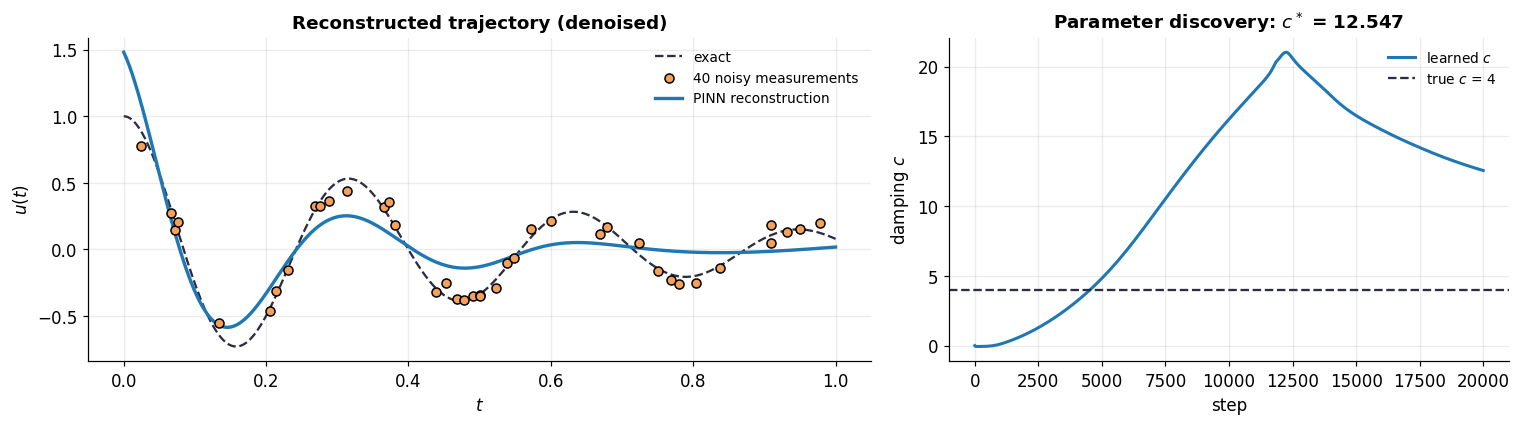

In [11]:
u_inv_pred = predict_1d(pinn_inv)

fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
ax.plot(t_test, u_test, "--", color=C["exact"], lw=1.5, label="exact")
ax.scatter(t_inv, u_inv, color=C["data"], edgecolor="k", s=35, zorder=5, label=f"{N_INV} noisy measurements")
ax.plot(t_test, u_inv_pred, color=C["pinn"], lw=2.2, label="PINN reconstruction")
ax.set(title="Reconstructed trajectory (denoised)", xlabel="$t$", ylabel="$u(t)$"); ax.legend(fontsize=9)

ax = axes[1]
ax.plot(c_history, color=C["pinn"], lw=2, label="learned $c$")
ax.axhline(c_true, color=C["exact"], ls="--", label=f"true $c$ = {c_true:g}")
ax.set(title=f"Parameter discovery: $c^*$ = {c_found:.3f}", xlabel="step", ylabel="damping $c$")
ax.legend(fontsize=9)
fig.tight_layout(); savefig(fig, "06_inverse_problem"); plt.show()

---
## 3. A partial differential equation — the 1-D heat equation

Now the input is two-dimensional, $(x, t)$, and the model must reconstruct a whole temperature field. Heat diffusion in a rod with both ends held at zero temperature:

$$
\frac{\partial u}{\partial t} = \alpha\,\frac{\partial^2 u}{\partial x^2},
\qquad x\in[0,1],\ t\in[0,1],
$$
$$
u(x,0) = \sin(\pi x) + \tfrac12\sin(3\pi x), \qquad u(0,t) = u(1,t) = 0 .
$$

With $\alpha = 0.05$, separation of variables gives the exact solution

$$
u(x,t) = \sin(\pi x)\,e^{-\alpha\pi^2 t} + \tfrac12\sin(3\pi x)\,e^{-9\alpha\pi^2 t},
$$

where the high-frequency mode decays nine times faster than the fundamental: a nice test of whether a model has learned the *dynamics*, not just a curve fit.

**Data:** five temperature sensors along the rod, recording (with noise) only during the first half of the experiment, $t \le 0.5$, plus the known initial and boundary conditions.

### Loss functions
Writing $\hat u_\theta(x,t)$ for the network,

$$
\mathcal{L}_{\text{NN}} = \mathcal{L}_{\text{sensors}} + \lambda_{\text{ic}}\,\frac{1}{N_{ic}}\sum\big(\hat u_\theta(x_i,0) - u_0(x_i)\big)^2 + \lambda_{\text{bc}}\,\frac{1}{N_{bc}}\sum \hat u_\theta(x_b,t_b)^2,
$$
$$
\mathcal{L}_{\text{PINN}} = \mathcal{L}_{\text{NN}} + \lambda_{\text{pde}}\,\frac{1}{N_c}\sum_{j}\Big(\partial_t\hat u_\theta - \alpha\,\partial_{xx}\hat u_\theta\Big)^2\Big|_{(x_j,t_j)} .
$$

Both models are trained with Adam followed by L-BFGS, a common two-stage recipe for PINNs (Adam escapes the poor early landscape; L-BFGS polishes to high precision).

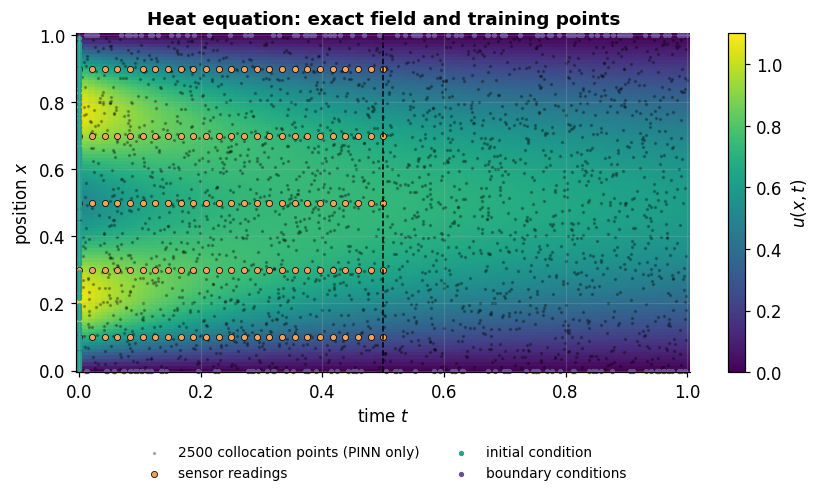

In [12]:
alpha = 0.05

def exact_heat(x, t):
    return (np.sin(np.pi * x) * np.exp(-alpha * np.pi**2 * t)
            + 0.5 * np.sin(3 * np.pi * x) * np.exp(-9 * alpha * np.pi**2 * t))

set_seed()
# Sensors: 5 fixed positions, 25 noisy readings each, only for t <= 0.5
T_SENSE, NOISE_HEAT = 0.5, 0.01
x_sensors = np.array([0.1, 0.3, 0.5, 0.7, 0.9])
t_sense = np.linspace(0, T_SENSE, 25)
XS, TS = np.meshgrid(x_sensors, t_sense, indexing="ij")
xs, ts = XS.reshape(-1, 1), TS.reshape(-1, 1)
us = exact_heat(xs, ts) + NOISE_HEAT * np.random.randn(*xs.shape)

# Initial and boundary conditions
N_IC, N_BC, N_PDE = 200, 200, 2500
x_ic = np.random.rand(N_IC, 1);  t_ic = np.zeros_like(x_ic);  u_ic = exact_heat(x_ic, 0.0)
t_bc = np.random.rand(N_BC, 1);  x_bc = np.where(np.arange(N_BC)[:, None] % 2 == 0, 0.0, 1.0)

# Collocation points across the whole space-time domain
x_pde, t_pde = np.random.rand(N_PDE, 1), np.random.rand(N_PDE, 1)

XT = lambda x, t: to_tensor(np.hstack([x, t]))
xt_s, u_s = XT(xs, ts), to_tensor(us)
xt_ic, u_ic_t = XT(x_ic, t_ic), to_tensor(u_ic)
xt_bc = XT(x_bc, t_bc)
x_pde_t, t_pde_t = to_tensor(x_pde, requires_grad=True), to_tensor(t_pde, requires_grad=True)

# Evaluation grid
nx, nt = 101, 101
xg, tg = np.linspace(0, 1, nx), np.linspace(0, 1, nt)
XG, TG = np.meshgrid(xg, tg, indexing="ij")
U_exact = exact_heat(XG, TG)
xt_grid = XT(XG.reshape(-1, 1), TG.reshape(-1, 1))

fig, ax = plt.subplots(figsize=(9, 4))
pcm = ax.pcolormesh(TG, XG, U_exact, cmap="viridis", shading="auto", vmin=0, vmax=1.1)
ax.scatter(t_pde, x_pde, s=1.5, color="k", alpha=0.25, label=f"{N_PDE} collocation points (PINN only)")
ax.scatter(ts, xs, s=16, color=C["data"], edgecolor="k", lw=0.5, label="sensor readings")
ax.scatter(t_ic, x_ic, s=6, color="#2a9d8f", label="initial condition")
ax.scatter(t_bc, x_bc, s=6, color="#6a4c93", label="boundary conditions", clip_on=False)
ax.axvline(T_SENSE, color="k", ls="--", lw=1)
fig.colorbar(pcm, ax=ax, label="$u(x,t)$")
ax.set(xlabel="time $t$", ylabel="position $x$", title="Heat equation: exact field and training points")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, fontsize=9)
savefig(fig, "07_heat_setup"); plt.show()

In [13]:
LAMBDA_IC_H, LAMBDA_BC_H, LAMBDA_PDE = 1.0, 1.0, 1.0

def heat_residual(model, x, t):
    u = model(torch.cat([x, t], dim=1))
    u_t = grad(u, t)
    u_x = grad(u, x)
    u_xx = grad(u_x, x)
    return u_t - alpha * u_xx

def heat_loss(model, use_physics):
    loss_s = torch.mean((model(xt_s) - u_s) ** 2)
    loss_ic = torch.mean((model(xt_ic) - u_ic_t) ** 2)
    loss_bc = torch.mean(model(xt_bc) ** 2)
    parts = {"sensors": loss_s, "ic": loss_ic, "bc": loss_bc}
    total = loss_s + LAMBDA_IC_H * loss_ic + LAMBDA_BC_H * loss_bc
    if use_physics:                                   # <- again, the only difference
        loss_pde = torch.mean(heat_residual(model, x_pde_t, t_pde_t) ** 2)
        parts["pde"] = loss_pde
        total = total + LAMBDA_PDE * loss_pde
    return total, parts

def predict_field(model):
    with torch.no_grad():
        return model(xt_grid).cpu().numpy().reshape(nx, nt)

N_ADAM_HEAT, N_LBFGS_HEAT = 5000, 500
set_seed(); nn_heat = MLP(2, 1, width=50, depth=4).to(DEVICE)
set_seed(); pinn_heat = MLP(2, 1, width=50, depth=4).to(DEVICE)

loss_nn_h = lambda mdl: heat_loss(mdl, use_physics=False)
loss_pinn_h = lambda mdl: heat_loss(mdl, use_physics=True)

hist_nn_heat, _, t1 = train_adam(nn_heat, loss_nn_h, N_ADAM_HEAT, log_every=1000, tag="NN  ")
t2 = train_lbfgs(nn_heat, loss_nn_h, hist_nn_heat, N_LBFGS_HEAT, tag="NN  ")
hist_pinn_heat, _, t3 = train_adam(pinn_heat, loss_pinn_h, N_ADAM_HEAT, log_every=1000, tag="PINN")
t4 = train_lbfgs(pinn_heat, loss_pinn_h, hist_pinn_heat, N_LBFGS_HEAT, tag="PINN")
time_nn_heat, time_pinn_heat = t1 + t2, t3 + t4

[NN  ] step      1 | loss=1.065e+00 | sensors=4.76e-01  ic=5.72e-01  bc=1.73e-02
[NN  ] step   1000 | loss=7.107e-03 | sensors=2.44e-03  ic=2.72e-03  bc=1.94e-03
[NN  ] step   2000 | loss=7.391e-04 | sensors=5.38e-04  ic=1.42e-04  bc=5.86e-05
[NN  ] step   3000 | loss=2.419e-04 | sensors=1.89e-04  ic=3.01e-05  bc=2.24e-05
[NN  ] step   4000 | loss=1.433e-04 | sensors=1.14e-04  ic=1.38e-05  bc=1.54e-05
[NN  ] step   5000 | loss=1.140e-04 | sensors=9.33e-05  ic=8.97e-06  bc=1.17e-05
[NN  ] done in 33.4s
[NN  ] L-BFGS done in 7.2s | final loss=7.464e-05
[PINN] step      1 | loss=1.121e+00 | sensors=4.76e-01  ic=5.72e-01  bc=1.73e-02  pde=5.55e-02
[PINN] step   1000 | loss=6.603e-02 | sensors=7.56e-03  ic=4.11e-02  bc=1.23e-02  pde=5.11e-03
[PINN] step   2000 | loss=3.500e-03 | sensors=1.16e-04  ic=1.21e-03  bc=8.14e-04  pde=1.36e-03
[PINN] step   3000 | loss=1.306e-03 | sensors=9.09e-05  ic=2.96e-04  bc=1.80e-04  pde=7.39e-04
[PINN] step   4000 | loss=7.280e-04 | sensors=8.78e-05  ic=1.27

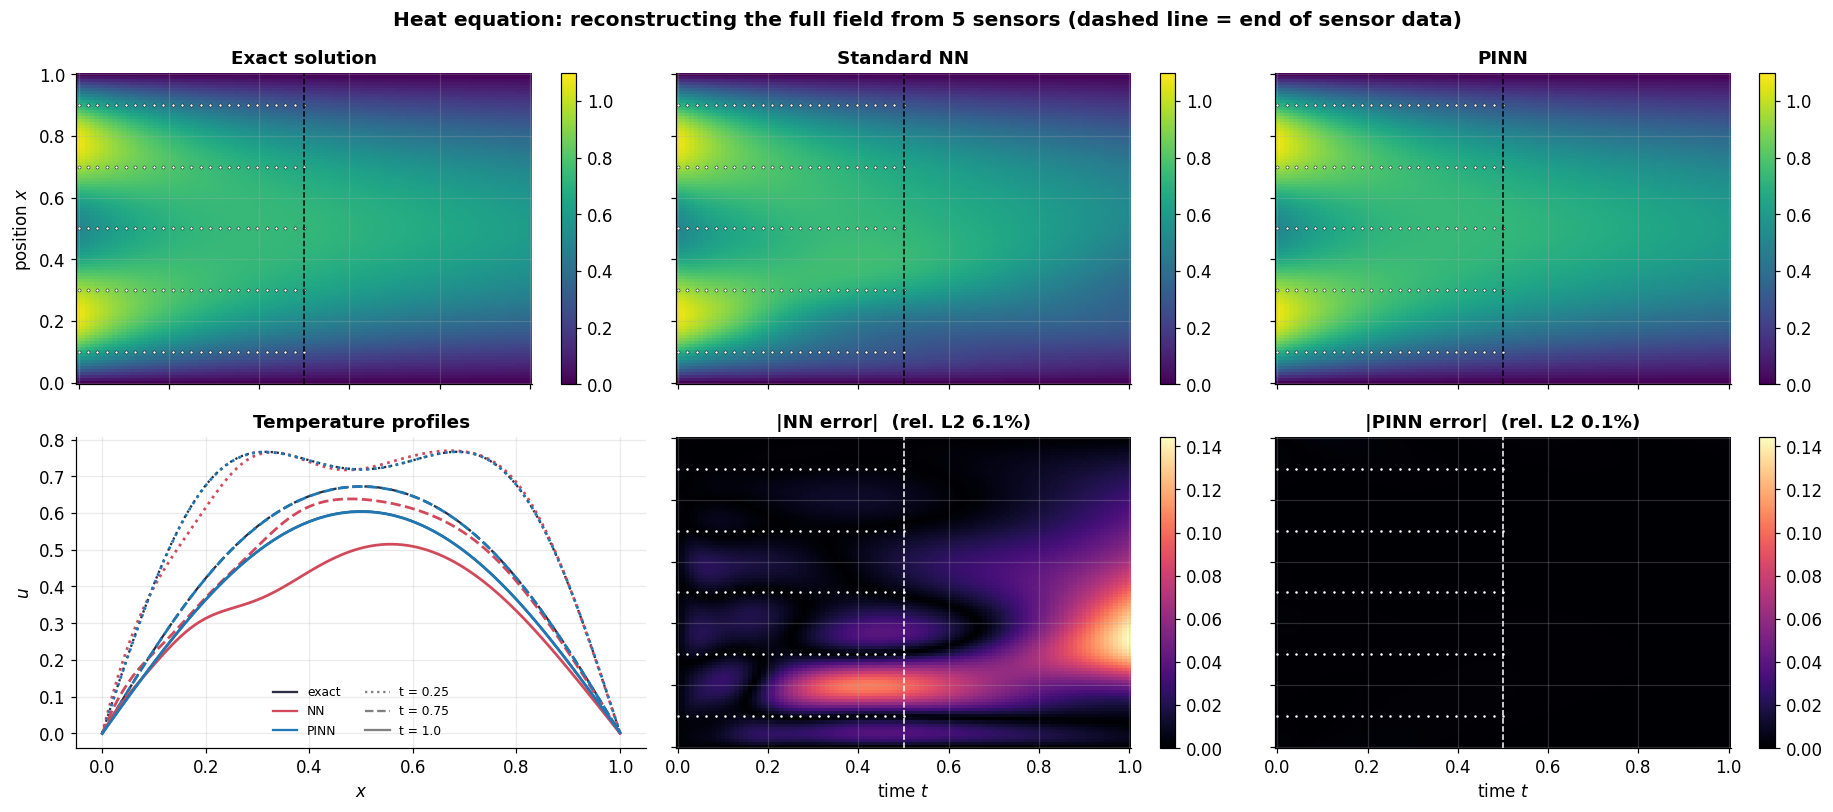

model     error (t <= 0.5)     error (t > 0.5)     overall
NN                   3.77%               8.82%       6.07%
PINN                 0.13%               0.11%       0.12%


In [14]:
U_nn, U_pinn = predict_field(nn_heat), predict_field(pinn_heat)
early = TG <= T_SENSE
metrics_heat = {
    name: {"observed": rel_l2(U[early], U_exact[early]), "extrapolated": rel_l2(U[~early], U_exact[~early]),
           "overall": rel_l2(U, U_exact)}
    for name, U in [("NN", U_nn), ("PINN", U_pinn)]
}

err_max = max(np.abs(U_nn - U_exact).max(), np.abs(U_pinn - U_exact).max())
fig, axes = plt.subplots(2, 3, figsize=(17, 7.5), sharex=True, sharey=True)
panels = [
    (axes[0, 0], U_exact, "Exact solution", "viridis", (0, 1.1)),
    (axes[0, 1], U_nn, "Standard NN", "viridis", (0, 1.1)),
    (axes[0, 2], U_pinn, "PINN", "viridis", (0, 1.1)),
    (axes[1, 1], np.abs(U_nn - U_exact), f"|NN error|  (rel. L2 {metrics_heat['NN']['overall']:.1%})", "magma", (0, err_max)),
    (axes[1, 2], np.abs(U_pinn - U_exact), f"|PINN error|  (rel. L2 {metrics_heat['PINN']['overall']:.1%})", "magma", (0, err_max)),
]
for ax, Z, title, cmap, (vmin, vmax) in panels:
    pcm = ax.pcolormesh(TG, XG, Z, cmap=cmap, shading="auto", vmin=vmin, vmax=vmax)
    ax.scatter(ts, xs, s=4, color="w", edgecolor="k", lw=0.3)
    ax.axvline(T_SENSE, color="w" if cmap == "magma" else "k", ls="--", lw=1)
    ax.set_title(title)
    fig.colorbar(pcm, ax=ax)

# Bottom-left panel: time slices
ax = axes[1, 0]
ax.remove()
ax = fig.add_subplot(2, 3, 4)
for t_slice, ls in [(0.25, ":"), (0.75, "--"), (1.0, "-")]:
    j = np.argmin(np.abs(tg - t_slice))
    ax.plot(xg, U_exact[:, j], color=C["exact"], ls=ls, lw=1.5)
    ax.plot(xg, U_nn[:, j], color=C["nn"], ls=ls, lw=1.8)
    ax.plot(xg, U_pinn[:, j], color=C["pinn"], ls=ls, lw=1.8)
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], color=C["exact"], label="exact"), Line2D([], [], color=C["nn"], label="NN"),
                   Line2D([], [], color=C["pinn"], label="PINN"), Line2D([], [], color="gray", ls=":", label="t = 0.25"),
                   Line2D([], [], color="gray", ls="--", label="t = 0.75"), Line2D([], [], color="gray", ls="-", label="t = 1.0")],
          fontsize=8, ncol=2)
ax.set(title="Temperature profiles", xlabel="$x$", ylabel="$u$")

for a in axes[1, 1:]: a.set_xlabel("time $t$")
axes[0, 0].set_ylabel("position $x$"); axes[1, 1].set_ylabel("")
fig.suptitle("Heat equation: reconstructing the full field from 5 sensors (dashed line = end of sensor data)",
             fontweight="bold")
fig.tight_layout(); savefig(fig, "08_heat_comparison"); plt.show()

print(f"{'model':<6}{'error (t <= 0.5)':>20}{'error (t > 0.5)':>20}{'overall':>12}")
for name, e in metrics_heat.items():
    print(f"{name:<6}{e['observed']:>20.2%}{e['extrapolated']:>20.2%}{e['overall']:>12.2%}")

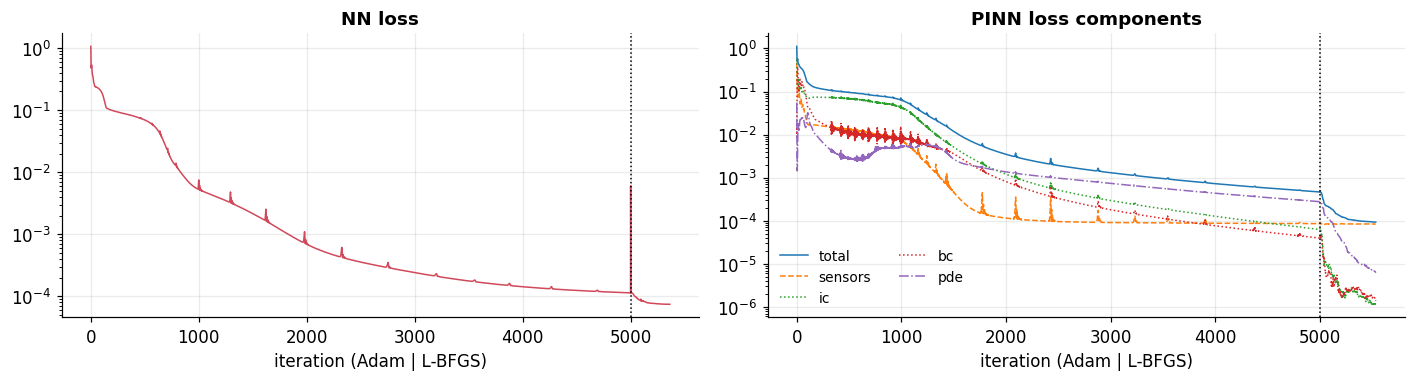

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
axes[0].semilogy(hist_nn_heat["total"], color=C["nn"], lw=1)
axes[0].axvline(N_ADAM_HEAT, color="k", ls=":", lw=1)
axes[0].set(title="NN loss", xlabel="iteration (Adam | L-BFGS)")
for key, ls in [("total", "-"), ("sensors", "--"), ("ic", ":"), ("bc", ":"), ("pde", "-.")]:
    axes[1].semilogy(hist_pinn_heat[key], ls, lw=1, label=key)
axes[1].axvline(N_ADAM_HEAT, color="k", ls=":", lw=1)
axes[1].set(title="PINN loss components", xlabel="iteration (Adam | L-BFGS)")
axes[1].legend(fontsize=9, ncol=2)
fig.tight_layout(); savefig(fig, "09_heat_losses"); plt.show()

---
## 4. Summary

Relative L2 error                                 NN      PINN   improvement
----------------------------------------------------------------------------
Oscillator — interpolation (t <= 0.4)          3.32%     0.45%          7.3x
Oscillator — extrapolation (t > 0.4)         992.21%     0.35%       2807.9x
Heat eq. — observed period (t <= 0.5)          3.77%     0.13%         28.7x
Heat eq. — extrapolation (t > 0.5)             8.82%     0.11%         83.8x
----------------------------------------------------------------------------
Inverse problem: true c = 4.0, discovered c = 12.547 (213.67% error)
Training time (s) — oscillator NN 118 | PINN 267;  heat NN 41 | PINN 99


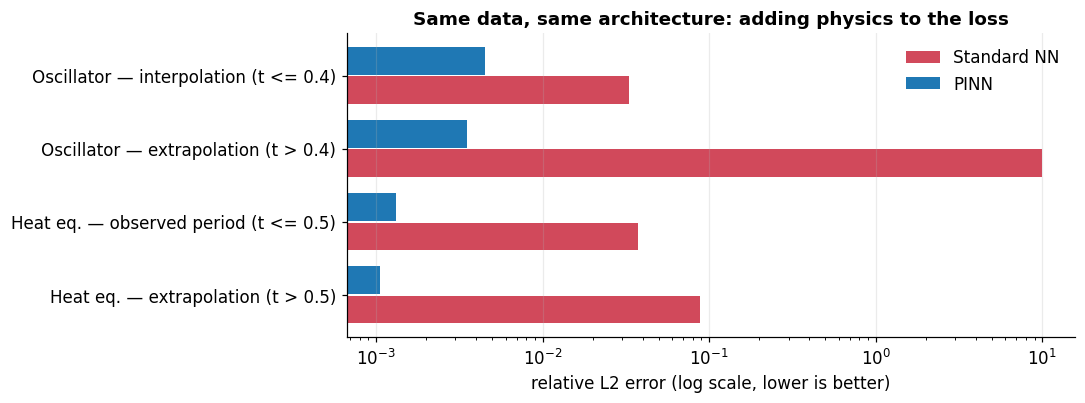

In [16]:
rows = [
    ("Oscillator — interpolation (t <= 0.4)", metrics_osc["NN"]["observed"], metrics_osc["PINN"]["observed"]),
    ("Oscillator — extrapolation (t > 0.4)", metrics_osc["NN"]["extrapolated"], metrics_osc["PINN"]["extrapolated"]),
    ("Heat eq. — observed period (t <= 0.5)", metrics_heat["NN"]["observed"], metrics_heat["PINN"]["observed"]),
    ("Heat eq. — extrapolation (t > 0.5)", metrics_heat["NN"]["extrapolated"], metrics_heat["PINN"]["extrapolated"]),
]

print(f"{'Relative L2 error':<42}{'NN':>10}{'PINN':>10}{'improvement':>14}")
print("-" * 76)
for label, e_nn, e_pinn in rows:
    print(f"{label:<42}{e_nn:>10.2%}{e_pinn:>10.2%}{e_nn / e_pinn:>13.1f}x")
print("-" * 76)
print(f"Inverse problem: true c = {c_true}, discovered c = {c_found:.3f} ({abs(c_found - c_true) / c_true:.2%} error)")
print(f"Training time (s) — oscillator NN {time_nn_osc:.0f} | PINN {time_pinn_osc:.0f};  "
      f"heat NN {time_nn_heat:.0f} | PINN {time_pinn_heat:.0f}")

fig, ax = plt.subplots(figsize=(10, 3.8))
y = np.arange(len(rows))
ax.barh(y + 0.2, [r[1] for r in rows], height=0.38, color=C["nn"], label="Standard NN")
ax.barh(y - 0.2, [r[2] for r in rows], height=0.38, color=C["pinn"], label="PINN")
ax.set_yticks(y, [r[0] for r in rows]); ax.invert_yaxis()
ax.set_xscale("log"); ax.set_xlabel("relative L2 error (log scale, lower is better)")
ax.set_title("Same data, same architecture: adding physics to the loss")
ax.legend(); ax.grid(axis="y", visible=False)
fig.tight_layout(); savefig(fig, "10_summary"); plt.show()

### Key takeaways

1. **Physics is a regulariser that generalises.** With identical data and architecture, the standard NN matches the PINN *where it has data* but fails beyond it. The physics residual constrains the model everywhere collocation points are placed, which is exactly where data is missing.
2. **Low training loss ≠ valid model.** The baseline NN reaches a tiny data loss while violating the governing equation by orders of magnitude. Evaluating the physics residual is a cheap, label-free sanity check for *any* surrogate model.
3. **Inverse problems come for free.** Turning an unknown coefficient into a trainable parameter lets the PINN recover it from noisy, sparse measurements, which a purely data-driven model cannot do.
4. **Mesh-free.** The PINN never builds a grid or a stencil. Derivatives are exact (automatic differentiation), and the same code handles irregular domains or scattered sensors.

### Limitations

* **Cost.** For a single forward solve of a known, simple PDE, a classical solver (finite differences / finite elements) is faster and more accurate. PINNs shine for inverse problems, sparse noisy data, and high-dimensional or parametric settings.
* **Loss balancing.** Results depend on $\lambda_{\text{ic}}, \lambda_{\text{bc}}, \lambda_{\text{phys}}$; I used non-dimensionalisation to make them $\mathcal{O}(1)$. Adaptive schemes (learning-rate annealing, NTK-based weighting, self-adaptive weights) automate this.
* **Spectral bias & long horizons.** Plain MLPs struggle with high frequencies and long time windows. Remedies: Fourier-feature embeddings, causal training, time-marching / domain decomposition (XPINNs).
* **Collocation strategy.** Residual-based adaptive refinement (RAR) places more points where the residual is largest.

### References
* M. Raissi, P. Perdikaris, G. E. Karniadakis, *Physics-informed neural networks: A deep learning framework for solving forward and inverse problems involving nonlinear partial differential equations*, J. Comput. Phys. 378 (2019) 686–707.
* G. E. Karniadakis et al., *Physics-informed machine learning*, Nature Reviews Physics 3 (2021) 422–440.
* S. Wang, Y. Teng, P. Perdikaris, *Understanding and mitigating gradient flow pathologies in physics-informed neural networks*, SIAM J. Sci. Comput. 43 (2021).
* L. Lu et al., *DeepXDE: A deep learning library for solving differential equations*, SIAM Review 63 (2021).